# Lab: Relationships Between Quantitative Features

Use a historical mammal sleep dataset to compare dreaming, non-dreaming, and total sleep. Use non-dreaming versus total sleep as the main model, then examine whether danger and predation ratings add information. Finally, investigate the nonlinear pattern between gestation time and total sleep.

Support conclusions with the plots and calculations. Explain how well a straight line follows the points and how much variation remains.

## Learning goals

- Describe whether points trend upward or downward, follow a straight or curved pattern, cluster closely around that pattern, or include unusual observations.
- Calculate correlation and interpret R-squared on the correct response scale.
- Recognize nonlinear patterns and compare original gestation with log-transformed gestation.
- Examine additional categorical features visually and compare model R-squared on the same observations.
- Check missing codes, units, category counts, and transformations.
- Distinguish improved fit to observed records from causation and performance on new data.

## The reproducible analysis workflow

1. **Question:** What do we want to learn?
2. **Data:** Which observations and features can answer it?
3. **Evidence:** What should we calculate and display?
4. **Check:** Does the result make sense in context and agree with the original records?
5. **Conclusion:** What claim is supported?
6. **Limitation:** What should we avoid concluding?

Complete each investigation in order. Use separate cells for individual operations and add cells as needed. Give figures informative titles, named colors, and axis labels with units or transformations. Use the default point transparency and line widths. `ci=None` can omit confidence bands so the patterns and group lines are easier to compare.

## Using AI tools responsibly

You may use AI to ask questions, debug code, or receive feedback. You remain responsible for understanding the code and checking every claim against the source and your output. Complete the AI-use reflection at the end.

## Dataset and context

Use the [StatLib mammal sleep data hosted by UC Berkeley](https://www.stat.berkeley.edu/~spector/s100/data/sleep.dat) and its [measurement dictionary](https://www.stat.berkeley.edu/~spector/s100/data/sleep.html). A local copy is supplied as `data/mammal_sleep.csv`.

The supplied `data/mammal_sleep.csv` contains all 62 records and 11 features, including species names and both sleep phases. One row describes a mammal species, not an individual animal or a night. The data trace to Allison and Cicchetti's 1976 study, [Sleep in mammals: ecological and constitutional correlates](https://pubmed.ncbi.nlm.nih.gov/982039/). This is a historical comparative dataset, not a random sample of all mammals; individual collection dates are not supplied.

Course preparation preserves all values and names, gives columns descriptive names, and converts the source's `-999` missing code into blank CSV fields. Use ordinary `pd.read_csv()`; blanks are recognized as missing. The terms dreaming and non-dreaming identify the study's sleep-phase measurements; they are not direct reports of an animal's subjective dream experiences.

### Data dictionary

| Feature | Meaning and units or codes |
| --- | --- |
| `species` | Species label as recorded in the historical source |
| `non_dreaming_sleep` | Non-dreaming sleep in hours per day |
| `dreaming_sleep` | Dreaming sleep in hours per day |
| `body_weight` | Body weight in kilograms |
| `brain_weight` | Brain weight in grams |
| `max_life_span` | Maximum lifespan in years |
| `gestation_time` | Gestation duration in days |
| `predation_index` | Ordered rating, 1–5: lower to higher likelihood of being preyed upon |
| `sleep_exposure_index` | Ordered rating, 1–5: more protected to more exposed sleeping conditions |
| `danger_index` | Ordered rating, 1–5: lower to higher overall danger from other animals |
| `total_sleep` | Total sleep in hours per day; sum of the two phases |

The indices are **ordinal categorical features**, even though stored as numbers. A one-point difference is not a documented equal increment of physical risk. Overall danger incorporates predation, sleep exposure, and other information, so these ratings are not independent measurements. In our models, represent rating levels as categories rather than assuming equal numerical spacing.

## Load and inspect the data

In [2]:
# Import NumPy, Pandas, Matplotlib pyplot, and Seaborn.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# Read data/mammal_sleep.csv into mammals_df; blank fields are recognized as missing.
mammals_df = pd.read_csv("data/mammal_sleep.csv")

In [4]:
# Display the first five rows.
mammals_df.head()

,species,body_weight,brain_weight,non_dreaming_sleep,dreaming_sleep,total_sleep,max_life_span,gestation_time,predation_index,sleep_exposure_index,danger_index
0,African elephant,6654.000,5712.0,NaN,NaN,3.3,38.6,645.0,3,5,3
1,African giant pouched rat,1.000,6.6,6.3,2.0,8.3,4.5,42.0,3,1,3
2,Arctic Fox,3.385,44.5,NaN,NaN,12.5,14.0,60.0,1,1,1
3,Arctic ground squirrel,0.920,5.7,NaN,NaN,16.5,NaN,25.0,5,2,3
4,Asian elephant,2547.000,4603.0,2.1,1.8,3.9,69.0,624.0,3,5,4


In [5]:
# Display the last five rows.
mammals_df.tail()

,species,body_weight,brain_weight,non_dreaming_sleep,dreaming_sleep,total_sleep,max_life_span,gestation_time,predation_index,sleep_exposure_index,danger_index
57,Tree hyrax,2.000,12.3,4.9,0.5,5.4,7.5,200.0,3,1,3
58,Tree shrew,0.104,2.5,13.2,2.6,15.8,2.3,46.0,3,2,2
59,Vervet,4.190,58.0,9.7,0.6,10.3,24.0,210.0,4,3,4
60,Water opossum,3.500,3.9,12.8,6.6,19.4,3.0,14.0,2,1,1
61,Yellow-bellied marmot,4.050,17.0,NaN,NaN,NaN,13.0,38.0,3,1,1


In [6]:
# Display the shape.
mammals_df.shape

(62, 11)

In [7]:
# Use .info() to inspect the data storage types and non-missing values.
mammals_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62 entries, 0 to 61
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   species               62 non-null     object 
 1   body_weight           62 non-null     float64
 2   brain_weight          62 non-null     float64
 3   non_dreaming_sleep    48 non-null     float64
 4   dreaming_sleep        50 non-null     float64
 5   total_sleep           58 non-null     float64
 6   max_life_span         58 non-null     float64
 7   gestation_time        58 non-null     float64
 8   predation_index       62 non-null     int64  
 9   sleep_exposure_index  62 non-null     int64  
 10  danger_index          62 non-null     int64  
dtypes: float64(7), int64(3), object(1)
memory usage: 5.5+ KB


In [8]:
# Count missing values in every feature.
mammals_df.isnull().sum()

species                  0
body_weight              0
brain_weight             0
non_dreaming_sleep      14
dreaming_sleep          12
total_sleep              4
max_life_span            4
gestation_time           4
predation_index          0
sleep_exposure_index     0
danger_index             0
dtype: int64

**What does one row represent?**

Your answer: One row represents a mammal species and its data information. 

**Complete the table using the data dictionary, `.info()`, and `.isnull().sum()`. For data type, use categorical or quantitative. For data storage type, report the Pandas dtype. For missing values, report the count, including 0 when none are missing.**

| Feature | Data type | Data storage type | Missing values |
| --- | --- | --- | ---: |
| `species` | categorical | object | 0 |
| `non_dreaming_sleep` | quantitative | float64 | 14 |
| `dreaming_sleep` | quantitative | float64 | 12 |
| `body_weight` |quantitative  | float64 | 0 |
| `brain_weight` | quantitative | float64 | 0 |
| `max_life_span` | quantitative | float64 | 4 |
| `gestation_time` | quantitative | float64 | 4 |
| `predation_index` | categorical | int64 | 0 |
| `sleep_exposure_index` | categorical | int64 | 0 |
| `danger_index` | categorical | int64 | 0 |
| `total_sleep` | quantitative | float64 | 4 |

Your answer:

# Investigation 1: Dreaming, non-dreaming, and total sleep

## Step 1: Question

**How are dreaming and non-dreaming sleep related, and which phase has the stronger linear relationship with total sleep?**

Compare three relationships in hours per day: dreaming versus non-dreaming, dreaming versus total, and non-dreaming versus total. In the last comparison, use non-dreaming sleep on the horizontal axis and total sleep as the response. This is the main model for Investigation 2.

**Predict the direction and strength of each relationship. Which phase do you expect to be more strongly related to total sleep, and why?**

Your answer: I predict the non-dreaming phase to be strongly related to total sleep because dreams don't typically last long, also, you are less likely to wake up when you're not dreaming. Chances of waking up while dreaming might be higher since you can jolt awake due to what you're dreaming about. I think non-dreaming and total sleep will have a positive correlation, while dreaming and total sleep might have a negative correlation.

## Step 2: Data

Create `sleep_df` from records complete for `dreaming_sleep`, `non_dreaming_sleep`, `total_sleep`, `danger_index`, and `predation_index`. Use `.copy()` and keep `mammals_df` unchanged. Use this same subset in all three comparisons and in Investigation 2. How many records were removed from the dataset?

Check that sleep measurements are between 0 and 24 hours per day.

In [9]:
# Prepare sleep_df and check sample size and sleep ranges.
sleep_df = mammals_df.dropna().copy()
sleep_df.shape

(42, 11)

answer: 20 records were removed from the dataset

In [10]:
sleep_df.head()

,species,body_weight,brain_weight,non_dreaming_sleep,dreaming_sleep,total_sleep,max_life_span,gestation_time,predation_index,sleep_exposure_index,danger_index
1,African giant pouched rat,1.000,6.6,6.3,2.0,8.3,4.5,42.0,3,1,3
4,Asian elephant,2547.000,4603.0,2.1,1.8,3.9,69.0,624.0,3,5,4
5,Baboon,10.550,179.5,9.1,0.7,9.8,27.0,180.0,4,4,4
6,Big brown bat,0.023,0.3,15.8,3.9,19.7,19.0,35.0,1,1,1
7,Brazilian tapir,160.000,169.0,5.2,1.0,6.2,30.4,392.0,4,5,4


In [11]:
sleep_df.tail()

,species,body_weight,brain_weight,non_dreaming_sleep,dreaming_sleep,total_sleep,max_life_span,gestation_time,predation_index,sleep_exposure_index,danger_index
56,Tenrec,0.900,2.6,11.0,2.3,13.3,4.5,60.0,2,1,2
57,Tree hyrax,2.000,12.3,4.9,0.5,5.4,7.5,200.0,3,1,3
58,Tree shrew,0.104,2.5,13.2,2.6,15.8,2.3,46.0,3,2,2
59,Vervet,4.190,58.0,9.7,0.6,10.3,24.0,210.0,4,3,4
60,Water opossum,3.500,3.9,12.8,6.6,19.4,3.0,14.0,2,1,1


## Step 3: Evidence

Create three labeled regression plots with `sns.regplot()`: non-dreaming sleep versus dreaming sleep, total sleep versus dreaming sleep, and total sleep versus non-dreaming sleep. In each description, the feature after “versus” goes on the horizontal axis. Calculate the correlation and simple-line R-squared for each pair. Describe the points before relying on the fitted line.

When describing a scatterplot:

- **Direction:** Do the points generally rise or fall from left to right?
- **Form:** Does the overall pattern look roughly straight, curved, or have no clear shape? This describes the arrangement of the points, not the line drawn by the plotting function.
- **Strength:** How closely do the points follow that pattern?
- **Unusual observations:** Which points are far from most of the others?

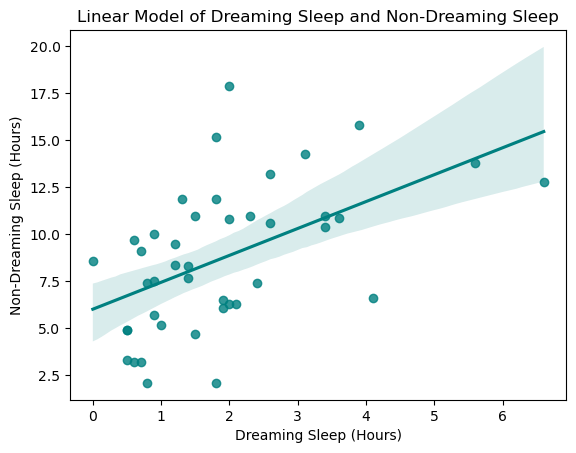

In [12]:
# Plot dreaming sleep and non-dreaming sleep.
sns.regplot(
    data=sleep_df,
    x="dreaming_sleep",
    y="non_dreaming_sleep",
    color="teal"
)
plt.title("Linear Model of Dreaming Sleep and Non-Dreaming Sleep")
plt.xlabel("Dreaming Sleep (Hours)")
plt.ylabel("Non-Dreaming Sleep (Hours)")
plt.show()

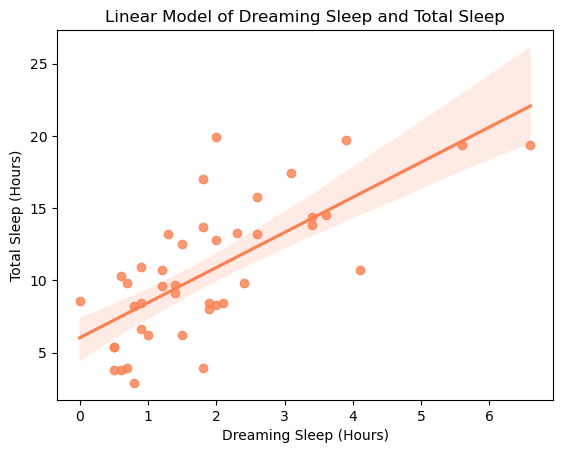

In [13]:
# Plot dreaming sleep and total sleep.
sns.regplot(
    data=sleep_df,
    x="dreaming_sleep",
    y="total_sleep",
    color="coral"
)
plt.title("Linear Model of Dreaming Sleep and Total Sleep")
plt.xlabel("Dreaming Sleep (Hours)")
plt.ylabel("Total Sleep (Hours)")
plt.show()

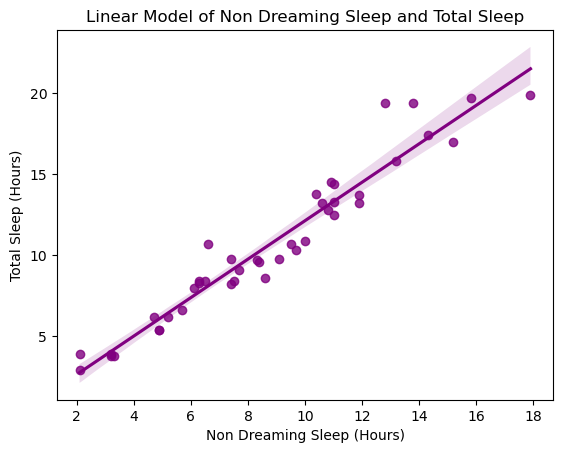

In [14]:
# Plot non-dreaming sleep and total sleep.
sns.regplot(
    data=sleep_df,
    x="non_dreaming_sleep",
    y="total_sleep",
    color="purple"
)
plt.title("Linear Model of Non Dreaming Sleep and Total Sleep")
plt.xlabel("Non Dreaming Sleep (Hours)")
plt.ylabel("Total Sleep (Hours)")
plt.show()

Calculate all three correlations and R-squared values.

In [15]:
# dreaming sleep and non-dreaming sleep
sleep_df[["dreaming_sleep", "non_dreaming_sleep"]].corr().round(3)

,dreaming_sleep,non_dreaming_sleep
dreaming_sleep,1.000,0.518
non_dreaming_sleep,0.518,1.000


In [16]:
r_squared = sleep_df[["dreaming_sleep", "non_dreaming_sleep"]].corr().loc[
    "dreaming_sleep", "non_dreaming_sleep"
] ** 2
round(r_squared, 3)

np.float64(0.269)

In [17]:
# dreaming sleep and total sleep
sleep_df[["dreaming_sleep", "total_sleep"]].corr().round(3)

,dreaming_sleep,total_sleep
dreaming_sleep,1.000,0.717
total_sleep,0.717,1.000


In [18]:
r_squared = sleep_df[["dreaming_sleep", "total_sleep"]].corr().loc[
    "dreaming_sleep", "total_sleep"
] ** 2
round(r_squared, 3)

np.float64(0.514)

In [19]:
# non-dreaming sleep and total sleep
sleep_df[["non_dreaming_sleep", "total_sleep"]].corr().round(3)

,non_dreaming_sleep,total_sleep
non_dreaming_sleep,1.000,0.968
total_sleep,0.968,1.000


In [20]:
r_squared = sleep_df[["non_dreaming_sleep", "total_sleep"]].corr().loc[
    "non_dreaming_sleep", "total_sleep"
] ** 2
round(r_squared, 3)

np.float64(0.936)

**For each plot, do the points generally rise or fall? Is their pattern roughly straight or curved, and how closely do they follow it? Identify any unusual observations. Which plot is best summarized by a straight line? Explain what its R-squared tells you about total sleep.**

Your answer: For the plot of Dreaming Sleep and Non-Dreaming Sleep, the points generally rise from left to right and their pattern is roughly straight, but the points don't follow the line too closely, it's a lot more scattered. There are a lot of points that fall off from the main pattern, especially between 1-4 hours of dreaming sleep.
For the plot of Dreaming Sleep and Total Sleep, the points rise from left to right and their pattern is roughly straight. The points on this plot follow the line a lot closer than the Dreaming Sleep and Non dreaming sleep plot. There are some points that fall off from the main pattern, but not as far as the Dreaming Sleep and Non dreaming sleep plot, but its still between 1-4 hours of dreaming sleep.
For the plot of Non Dreaming Sleep and Total Sleep, the points rise from left to right and their pattern is straight. This plot is best summarized by a straight line, with its points following the line closely. There are a few points that fall off from the main pattern, but not as far as the previous plots, between 12-14 hours of dreaming sleep. The R-squared calculation shows us that the model accounts for about 93.6% of the mammal variation in total sleep.


## Step 4: Check

Check that `dreaming_sleep + non_dreaming_sleep` agrees with `total_sleep` using `np.isclose()`, which allows for ordinary floating-point rounding. Display several original rows with their phase sum. Then display the three records with the longest non-dreaming sleep and locate their points on the non-dreaming versus total sleep plot. Do the plotted values agree with the records?

In [21]:
# Check the sleep-phase sum and display original measurements.
sleep_df_copy = sleep_df.copy()
sleep_df_copy["phase_sum"] = np.isclose(sleep_df["dreaming_sleep"] + sleep_df["non_dreaming_sleep"], sleep_df["total_sleep"])
sleep_df_copy.head(10)

,species,body_weight,brain_weight,non_dreaming_sleep,dreaming_sleep,total_sleep,max_life_span,gestation_time,predation_index,sleep_exposure_index,danger_index,phase_sum
1,African giant pouched rat,1.000,6.6,6.3,2.0,8.3,4.5,42.0,3,1,3,True
4,Asian elephant,2547.000,4603.0,2.1,1.8,3.9,69.0,624.0,3,5,4,True
5,Baboon,10.550,179.5,9.1,0.7,9.8,27.0,180.0,4,4,4,True
6,Big brown bat,0.023,0.3,15.8,3.9,19.7,19.0,35.0,1,1,1,True
7,Brazilian tapir,160.000,169.0,5.2,1.0,6.2,30.4,392.0,4,5,4,True
8,Cat,3.300,25.6,10.9,3.6,14.5,28.0,63.0,1,2,1,True
9,Chimpanzee,52.160,440.0,8.3,1.4,9.7,50.0,230.0,1,1,1,True
10,Chinchilla,0.425,6.4,11.0,1.5,12.5,7.0,112.0,5,4,4,True
11,Cow,465.000,423.0,3.2,0.7,3.9,30.0,281.0,5,5,5,True
14,Eastern American mole,0.075,1.2,6.3,2.1,8.4,3.5,42.0,1,1,1,True


In [22]:
# Inspect the three records with the longest non-dreaming sleep.
sleep_df_copy.nlargest(3, "non_dreaming_sleep")

,species,body_weight,brain_weight,non_dreaming_sleep,dreaming_sleep,total_sleep,max_life_span,gestation_time,predation_index,sleep_exposure_index,danger_index,phase_sum
32,Little brown bat,0.010,0.25,17.9,2.0,19.9,24.0,50.0,1,1,1,True
6,Big brown bat,0.023,0.30,15.8,3.9,19.7,19.0,35.0,1,1,1,True
41,Owl monkey,0.480,15.50,15.2,1.8,17.0,12.0,140.0,2,2,2,True


## Step 5: Conclusion

**Research question:** How are dreaming and non-dreaming sleep related, and which phase has the stronger linear relationship with total sleep?

**Do mammals that spend more time in dreaming sleep also tend to spend more time in non-dreaming sleep? Which phase is more strongly related to total sleep? Support your answers with the plots, correlations, and R-squared values. Did the results match your prediction?**

Your answer: Mammals that spend more time in dreaming sleep do tend to spend more time in non-dreaming sleep. The scatter plot of dreaming sleep and non-dreaming sleep is generally rising from left to right, and has a correlation of approximately 0.518, indicating a moderately positive linear association. The Non-dreaming sleep phase is more strongly realted to total sleep, the scatter plot shows a strongly close grouping as the points rise from left to right and it has a correlation of approximately 0.968. The R-squared calculation shows us that the model accounts for about 93.6% of the mammal variation in total sleep. The results matched some of my predictions. I did predict non-dreaming sleep to be strongly related to total sleep, but I incorrectly predicted that non-dreaming sleep and dreaming sleep would have a negative correlation. 

## Step 6: Limitation

**State two limitations specific to these sleep relationships. Explain why a stronger correlation is not automatically a better scientific explanation.**

Your answer: There were 20 records removed from the dataframe in order to not use the mmalls that contained null fields. These records could've impacted the results greatly. This dataset is also from a 1976 study, so some of the data may not be up to date. A stronger correlation is not autmoaically a better scientific explanation because in this scenrario, this correlation only involved two variables, which means it ignored other variables that may affect the correlation.  

# Investigation 2: Do danger and predation add information?

## Step 1: Question

**Do danger and predation categories add information about total sleep beyond non-dreaming sleep?**

**Predict whether each index will add substantial, small, or little visible information. What would you look for at comparable non-dreaming-sleep durations?**

Your answer: I predict both indexes might add a small amount of visible information because I feel like the likelihood of being preyed upon and the danger from other animals might affect how mammals sleep and how comfortable they feel falling asleep. I would look for a decrease in non-dreaming sleep durations.  

## Step 2: Data

Reuse `sleep_df` and its original sleep measurements. Count records for each danger and predation rating and display a cross-tabulation of the two indices. Keep all five original levels in their natural order. Higher predation index values mean a mammal is more likely to be preyed upon. Higher danger index values mean greater overall danger from other animals.

In [23]:
# Count the records at each danger and predation level.
sleep_df["danger_index"].value_counts()

danger_index
1    11
2    10
4     9
3     7
5     5
Name: count, dtype: int64

In [24]:
sleep_df["predation_index"].value_counts()

predation_index
2    11
5     9
1     8
3     7
4     7
Name: count, dtype: int64

In [25]:
# Cross-tabulate danger and predation ratings.
pd.crosstab(sleep_df["danger_index"], sleep_df["predation_index"])

predation_index,1,2,3,4,5
danger_index,,,,,
1,8,3,0,0,0
2,0,8,2,0,0
3,0,0,4,2,1
4,0,0,1,5,3
5,0,0,0,0,5


## Step 3: Evidence

Use `sns.lmplot()` twice on the non-dreaming–total sleep relationship, once colored by `danger_index` and once by `predation_index`. Set `hue_order=[1, 2, 3, 4, 5]`, use a named palette, and label the legend so the index direction is clear. The separate lines show group patterns; small groups may produce unstable lines. Compare groups where their non-dreaming-sleep ranges overlap.

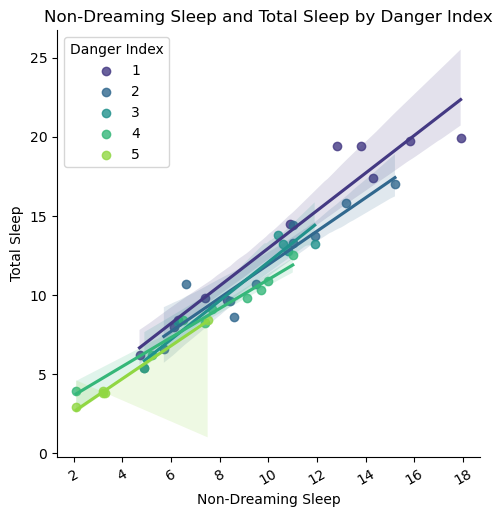

In [26]:
# Plot the non-dreaming–total sleep relationship by danger category.
sns.lmplot(
    data=sleep_df,
    x="non_dreaming_sleep",
    y="total_sleep",
    hue="danger_index",
    hue_order=[1, 2, 3, 4, 5],
    palette="viridis",
    legend=False
)
plt.title("Non-Dreaming Sleep and Total Sleep by Danger Index")
plt.xlabel("Non-Dreaming Sleep")
plt.ylabel("Total Sleep")
plt.xticks(rotation=30)
plt.legend(title="Danger Index")
plt.show()

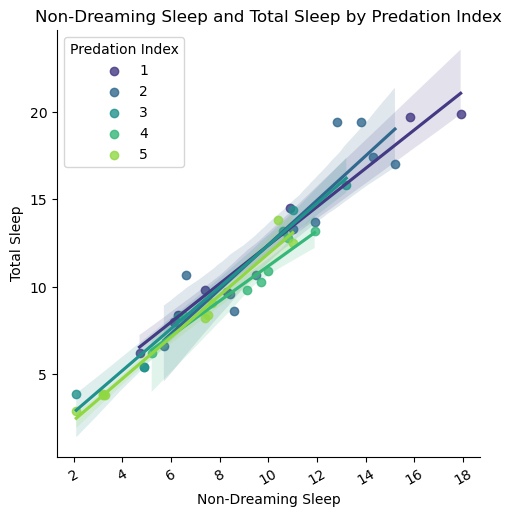

In [27]:
# Plot the non-dreaming–total sleep relationship by predation category.
sns.lmplot(
    data=sleep_df,
    x="non_dreaming_sleep",
    y="total_sleep",
    hue="predation_index",
    hue_order=[1, 2, 3, 4, 5],
    palette="viridis",
    legend=False
)
plt.title("Non-Dreaming Sleep and Total Sleep by Predation Index")
plt.xlabel("Non-Dreaming Sleep")
plt.ylabel("Total Sleep")
plt.xticks(rotation=30)
plt.legend(title="Predation Index")
plt.show()

**Describe overlap and separation in each plot. How do the group sizes and available non-dreaming-sleep ranges affect your interpretation?**

Your answer: Non-dreaming sleep and total sleep by danger index isn't as overlapped as non-dreaming sleep and total sleep by predation index. Based on the danger index plot, the lower the danger index, the more total sleep they get, and the higher the index, the less total sleep they get. A lower danger index means the mammal is less likely to be preyed on.
The group sizes and available sleep ranges affect interpretation because small groups may produce unstable lines, we don't have an equal amount of mamals in each index.

### Compare model R-squared

The supplied helper follows the lecture's least-squares calculation. Read and run it; you do not need to recreate its matrix operations. `pd.get_dummies()` represents each rating with category indicators. `drop_first=True` chooses a reference level. This avoids assuming equal distances between index values.

These are **additive models**: one shared slope for the quantitative predictor and category-specific intercept adjustments. They differ from the separate group slopes in `lmplot()`. Compare the baseline, baseline plus danger, baseline plus predation, and baseline plus both, all on identical rows and the same response scale. Training R-squared cannot decrease when predictors are added to these nested models; an increase alone does not establish improved performance on new observations.

In [28]:
def calculate_r_squared(data, predictor, response, categorical_features):
    predictors = pd.get_dummies(
        data[[predictor, *categorical_features]],
        columns=categorical_features, drop_first=True, dtype=float
    )
    predictors.insert(0, "intercept", 1.0)
    x = predictors.to_numpy(dtype=float)
    y = data[response].to_numpy(dtype=float)
    fitted = x @ np.linalg.lstsq(x, y, rcond=None)[0]
    return 1 - ((y - fitted) ** 2).sum() / ((y - y.mean()) ** 2).sum()

In [29]:
# Build and display phase_comparison for the four models.
model_comparison = pd.Series(
    {
        "non_dreaming_sleep": calculate_r_squared(
            sleep_df, "non_dreaming_sleep", "total_sleep", []
        ),
        "non_dreaming_sleep + danger_index": calculate_r_squared(
            sleep_df, "non_dreaming_sleep", "total_sleep", ["danger_index"]
        ),
        "non_dreaming_sleep + predation_index": calculate_r_squared(
            sleep_df, "non_dreaming_sleep", "total_sleep", ["predation_index"]
        ),
        "non_dreaming_sleep + both categories": calculate_r_squared(
            sleep_df, "non_dreaming_sleep", "total_sleep",
            ["danger_index", "predation_index"]
        )
    },
    name="r_squared"
)

model_comparison.round(3)

non_dreaming_sleep                      0.936
non_dreaming_sleep + danger_index       0.950
non_dreaming_sleep + predation_index    0.944
non_dreaming_sleep + both categories    0.967
Name: r_squared, dtype: float64

## Step 4: Check

For each danger rating, display the smallest and largest non-dreaming sleep values using `.groupby()` and `.agg(["min", "max"])`. Repeat for predation ratings.

Compare these ranges with the group plots. Use the ranges to identify where two groups actually have observations at similar non-dreaming sleep durations.

In [30]:
# Display the non-dreaming sleep range for each danger and predation rating.
sleep_df.groupby("danger_index", observed=True)["non_dreaming_sleep"].agg(["min", "max"])

,min,max
danger_index,,
1,4.7,17.9
2,5.7,15.2
3,4.9,11.9
4,2.1,11.0
5,2.1,7.5


In [31]:
sleep_df.groupby("predation_index", observed=True)["non_dreaming_sleep"].agg(["min", "max"])

,min,max
predation_index,,
1,4.7,17.9
2,5.7,15.2
3,2.1,13.2
4,5.2,11.9
5,2.1,11.0


**Choose two danger groups. Over what range of non-dreaming sleep do both groups have observations? Why should you compare their lines within that shared range?**

Your answer: Both danger index 1 and 5 have observations within the range of 2.1-17.9 hours of non-dreaming sleep. Their lines should be compared within this range because it is the lower bound and upper bound of this feature and we will be able to see if there is a vast difference in sleep between the mammal that has a lower overall danger from other animals and the mammal that has a higher overall danger from other animals.  

## Step 5: Conclusion

**Research question:** Do danger and predation categories add information about total sleep beyond non-dreaming sleep?

**Does adding danger, predation, or both improve the model of total sleep? Report the four R-squared values and how much each changes from non-dreaming sleep alone. Are the improvements small or large? Explain how the group plots support your answer.**

Your answer: Adding both danger and predation imporves the model of total sleep because both features raise the r-squared variable the most. The r-squared value of non-dreaming sleep alone is .936, when danger index is added, it increases to .950, when predation index is added, it increases to .944, and when both features are added, the value increases to .967. 

## Step 6: Limitation

**Identify two limitations of this investigation.**

Your answer: There were 20 records removed from the dataframe in order to not use the mamals that contained null fields. These records could've impacted the results greatly. This dataset is also from a 1976 study, so some of the data may not be up to date.

# Investigation 3: Gestation time and total sleep

## Step 1: Question

**How is total sleep related to gestation time, and do danger and predation add information about sleep after accounting for gestation time?**

Gestation time is the length of a pregnancy, measured in days. We will compare it with total sleep, measured in hours per day, and see whether taking the logarithm of gestation time makes the pattern look straighter.

**Do you expect mammals with longer pregnancies to sleep more hours per day, fewer hours, or about the same amount? Explain your initial guess. You do not need prior knowledge about mammals; you will compare your prediction with the data.**

Your answer: I expect mammals with longer pregnancies to sleep fewer hours. I think pregnant mammals might stay on the move, especially if they are more prone to predators, since they might not feel safe. 

## Step 2: Data

Create `gestation_df` by dropping rows missing `gestation_time`, `total_sleep`, `danger_index`, or `predation_index`, then copying the result. How many records were removed from the dataset? Do not drop rows merely because maximum lifespan is missing. Check that gestation is positive and sleep is between 0 and 24 hours per day. Create `log10_gestation_time` only after checking the inputs.

In [32]:
# Prepare gestation_df and check counts and plausible ranges.
gestation_df = mammals_df.dropna(subset=["gestation_time", "total_sleep"]).copy()
gestation_df.head()

,species,body_weight,brain_weight,non_dreaming_sleep,dreaming_sleep,total_sleep,max_life_span,gestation_time,predation_index,sleep_exposure_index,danger_index
0,African elephant,6654.000,5712.0,NaN,NaN,3.3,38.6,645.0,3,5,3
1,African giant pouched rat,1.000,6.6,6.3,2.0,8.3,4.5,42.0,3,1,3
2,Arctic Fox,3.385,44.5,NaN,NaN,12.5,14.0,60.0,1,1,1
3,Arctic ground squirrel,0.920,5.7,NaN,NaN,16.5,NaN,25.0,5,2,3
4,Asian elephant,2547.000,4603.0,2.1,1.8,3.9,69.0,624.0,3,5,4


In [33]:
gestation_df.shape     # 8 records were dropped

(54, 11)

In [34]:
gestation_df.tail(7)

,species,body_weight,brain_weight,non_dreaming_sleep,dreaming_sleep,total_sleep,max_life_span,gestation_time,predation_index,sleep_exposure_index,danger_index
53,Sheep,55.500,175.0,3.2,0.6,3.8,20.0,151.0,5,5,5
54,Slow loris,1.400,12.5,NaN,NaN,11.0,12.7,90.0,2,2,2
56,Tenrec,0.900,2.6,11.0,2.3,13.3,4.5,60.0,2,1,2
57,Tree hyrax,2.000,12.3,4.9,0.5,5.4,7.5,200.0,3,1,3
58,Tree shrew,0.104,2.5,13.2,2.6,15.8,2.3,46.0,3,2,2
59,Vervet,4.190,58.0,9.7,0.6,10.3,24.0,210.0,4,3,4
60,Water opossum,3.500,3.9,12.8,6.6,19.4,3.0,14.0,2,1,1


In [35]:
print(gestation_df["gestation_time"] >= 0) 
print(gestation_df["total_sleep"] <= 24) 

0     True
1     True
2     True
3     True
4     True
5     True
6     True
7     True
8     True
9     True
10    True
11    True
13    True
14    True
15    True
16    True
17    True
21    True
22    True
23    True
24    True
25    True
26    True
27    True
28    True
29    True
31    True
32    True
33    True
34    True
35    True
36    True
37    True
38    True
39    True
41    True
42    True
43    True
44    True
45    True
46    True
47    True
48    True
49    True
50    True
51    True
52    True
53    True
54    True
56    True
57    True
58    True
59    True
60    True
Name: gestation_time, dtype: bool
0     True
1     True
2     True
3     True
4     True
5     True
6     True
7     True
8     True
9     True
10    True
11    True
13    True
14    True
15    True
16    True
17    True
21    True
22    True
23    True
24    True
25    True
26    True
27    True
28    True
29    True
31    True
32    True
33    True
34    True
35    True
36    True
37    True
38    Tru

In [36]:
gestation_df["log10_gestation_time"] = np.log10(gestation_df["gestation_time"])
gestation_df["log10_total_sleep"] = np.log10(gestation_df["total_sleep"])
gestation_df.head()

,species,body_weight,brain_weight,non_dreaming_sleep,dreaming_sleep,total_sleep,max_life_span,gestation_time,predation_index,sleep_exposure_index,danger_index,log10_gestation_time,log10_total_sleep
0,African elephant,6654.000,5712.0,NaN,NaN,3.3,38.6,645.0,3,5,3,2.809560,0.518514
1,African giant pouched rat,1.000,6.6,6.3,2.0,8.3,4.5,42.0,3,1,3,1.623249,0.919078
2,Arctic Fox,3.385,44.5,NaN,NaN,12.5,14.0,60.0,1,1,1,1.778151,1.096910
3,Arctic ground squirrel,0.920,5.7,NaN,NaN,16.5,NaN,25.0,5,2,3,1.397940,1.217484
4,Asian elephant,2547.000,4603.0,2.1,1.8,3.9,69.0,624.0,3,5,4,2.795185,0.591065


## Step 3: Evidence

Plot sleep against gestation on original scales, then against log10 gestation, leaving sleep in hours per day. Calculate correlation and simple-line R-squared for each. These R-squared values share the same response scale and observations. Compare whether the points follow a straight or curved pattern and how widely they are scattered, as well as the numerical summaries.

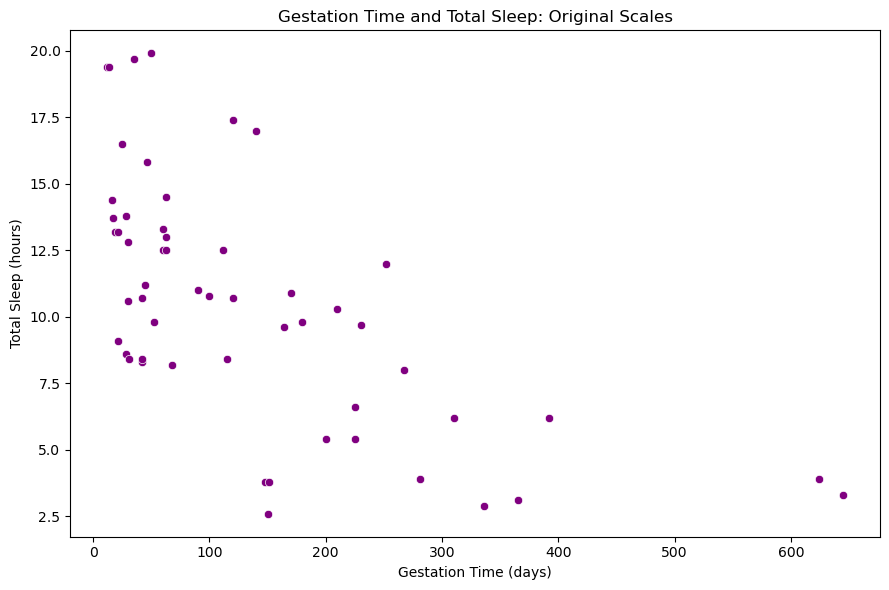

In [37]:
# Plot original gestation and sleep.
plt.figure(figsize=(9, 6))
sns.scatterplot(data=gestation_df, x="gestation_time", y="total_sleep", color="purple")
plt.title("Gestation Time and Total Sleep: Original Scales")
plt.xlabel("Gestation Time (days)")
plt.ylabel("Total Sleep (hours)")
plt.tight_layout()
plt.show()

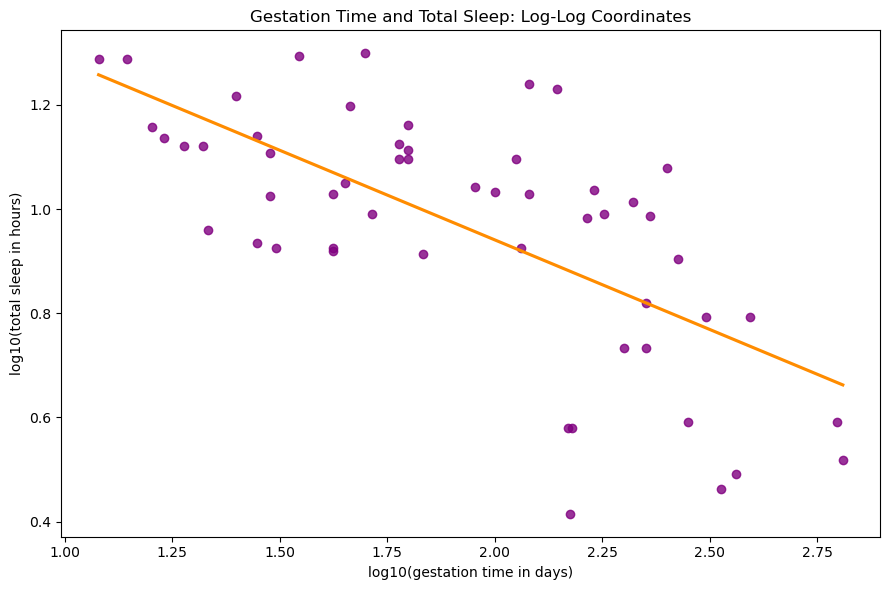

In [38]:
# Plot log gestation and sleep.
plt.figure(figsize=(9, 6))
sns.regplot(data=gestation_df, x="log10_gestation_time", y="log10_total_sleep", ci=None,
            line_kws={"color": "darkorange"}, color="purple")
plt.title("Gestation Time and Total Sleep: Log-Log Coordinates")
plt.xlabel("log10(gestation time in days)")
plt.ylabel("log10(total sleep in hours)")
plt.tight_layout()
plt.show()

In [39]:
# Calculate the two correlations and squared correlations.
pd.Series({
    "Original gestation time and total sleep": gestation_df["gestation_time"].corr(gestation_df["total_sleep"]),
    "log10(gestattion time) and log10(total sleep)": gestation_df["log10_gestation_time"].corr(gestation_df["total_sleep"])
}, name="Pearson correlation").round(3)

Original gestation time and total sleep         -0.631
log10(gestattion time) and log10(total sleep)   -0.664
Name: Pearson correlation, dtype: float64

In [40]:
r_squared = gestation_df[["gestation_time", "total_sleep"]].corr().loc[
    "gestation_time", "total_sleep"
] ** 2
round(r_squared, 3)

np.float64(0.399)

In [41]:
r_squared = gestation_df[["log10_gestation_time", "log10_total_sleep"]].corr().loc[
    "log10_gestation_time", "log10_total_sleep"
] ** 2
round(r_squared, 3)


np.float64(0.457)

**What changes when gestation is log-transformed? Does the transformation remove the scatter or only improve the straight-line summary modestly?**

Your answer: When gestation is log transformed, it takes the base-10 logarithm, so it compresses large values and changes how distances between points are interpreted. This tranformation helped remove some scatter and it improved the straight line summary.

Reuse the group-plot and model-comparison approach from Investigation 2, now using `log10_gestation_time` as the predictor and `total_sleep` as the response. Count observations at each rating level in this subset before interpreting the group lines. Examine danger and predation separately, then compare all four additive models on `gestation_df`.

In [42]:
# Count ratings in the sleep subset.
gestation_df["danger_index"].value_counts()

danger_index
1    16
2    12
3    10
4     9
5     7
Name: count, dtype: int64

In [43]:
gestation_df["predation_index"].value_counts()

predation_index
2    14
5    12
1    12
3     9
4     7
Name: count, dtype: int64

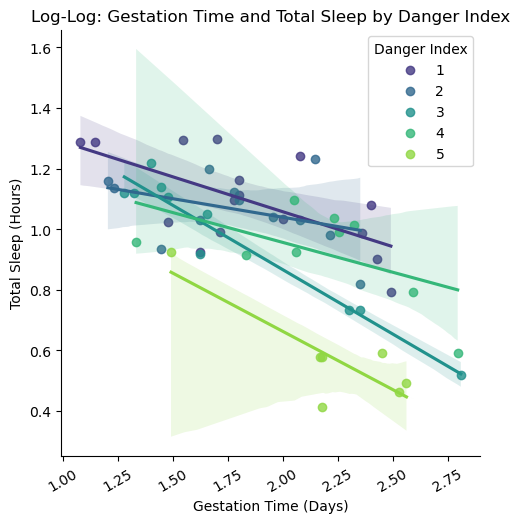

In [44]:
# Plot log gestation and sleep by danger.
sns.lmplot(
    data=gestation_df,
    x="log10_gestation_time",
    y="log10_total_sleep",
    hue="danger_index",
    hue_order=[1, 2, 3, 4, 5],
    palette="viridis",
    legend=False
)
plt.title("Log-Log: Gestation Time and Total Sleep by Danger Index")
plt.xlabel("Gestation Time (Days)")
plt.ylabel("Total Sleep (Hours)")
plt.xticks(rotation=30)
plt.legend(title="Danger Index")
plt.show()

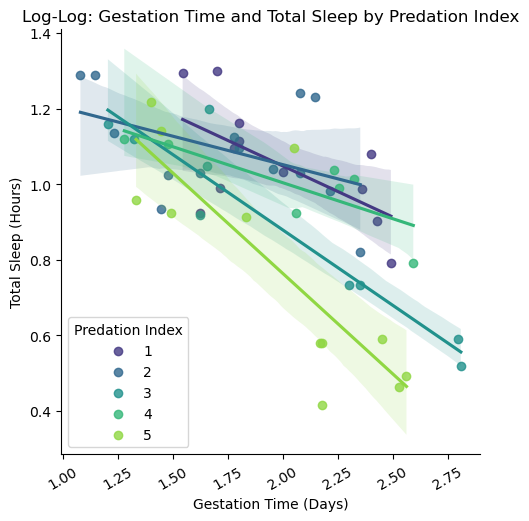

In [45]:
# Plot log gestation and sleep by predation.
sns.lmplot(
    data=gestation_df,
    x="log10_gestation_time",
    y="log10_total_sleep",
    hue="predation_index",
    hue_order=[1, 2, 3, 4, 5],
    palette="viridis",
    legend=False
)
plt.title("Log-Log: Gestation Time and Total Sleep by Predation Index")
plt.xlabel("Gestation Time (Days)")
plt.ylabel("Total Sleep (Hours)")
plt.xticks(rotation=30)
plt.legend(title="Predation Index")
plt.show()

In [46]:
# Build and display sleep_comparison for the four models.
sleep_comparison = pd.Series(
    {
        "log10_gestation_time": calculate_r_squared(
            gestation_df, "log10_gestation_time", "total_sleep", []
        ),
        "log10_gestation_time + danger_index": calculate_r_squared(
            gestation_df, "log10_gestation_time", "total_sleep", ["danger_index"]
        ),
        "log10_gestation_time + predation_index": calculate_r_squared(
            gestation_df, "log10_gestation_time", "total_sleep", ["predation_index"]
        ),
        "log10_gestation_time + both categories": calculate_r_squared(
            gestation_df, "log10_gestation_time", "total_sleep",
            ["danger_index", "predation_index"]
        )
    },
    name="r_squared"
)

sleep_comparison.round(3)

log10_gestation_time                      0.440
log10_gestation_time + danger_index       0.654
log10_gestation_time + predation_index    0.592
log10_gestation_time + both categories    0.694
Name: r_squared, dtype: float64

## Step 4: Check

For the first five records, display gestation time, its logarithm, and `10 ** log10_gestation_time`. Does reversing the logarithm recover the original number of days?

Display the records with the shortest and longest gestation times. Find their points in both plots and compare the recorded sleep hours with their vertical positions. The horizontal positions change when gestation is transformed; the sleep measurements stay the same.

In [47]:
# Reverse the logarithm for five records and compare with the original gestation times.
gestation_df_reverse = gestation_df[["gestation_time", "log10_gestation_time"]]
gestation_df_reverse["reverse"] = 10 ** gestation_df["log10_gestation_time"]
gestation_df_reverse.head()

C:\Users\lesly\AppData\Local\Temp\ipykernel_24460\3787421081.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  gestation_df_reverse["reverse"] = 10 ** gestation_df["log10_gestation_time"]


,gestation_time,log10_gestation_time,reverse
0,645.0,2.809560,645.0
1,42.0,1.623249,42.0
2,60.0,1.778151,60.0
3,25.0,1.397940,25.0
4,624.0,2.795185,624.0


In [48]:
# Inspect extreme gestation records.
gestation_df.nlargest(3, "gestation_time")

,species,body_weight,brain_weight,non_dreaming_sleep,dreaming_sleep,total_sleep,max_life_span,gestation_time,predation_index,sleep_exposure_index,danger_index,log10_gestation_time,log10_total_sleep
0,African elephant,6654.0,5712.0,NaN,NaN,3.3,38.6,645.0,3,5,3,2.809560,0.518514
4,Asian elephant,2547.0,4603.0,2.1,1.8,3.9,69.0,624.0,3,5,4,2.795185,0.591065
7,Brazilian tapir,160.0,169.0,5.2,1.0,6.2,30.4,392.0,4,5,4,2.593286,0.792392


In [49]:
gestation_df.nsmallest(3, "gestation_time")

,species,body_weight,brain_weight,non_dreaming_sleep,dreaming_sleep,total_sleep,max_life_span,gestation_time,predation_index,sleep_exposure_index,danger_index,log10_gestation_time,log10_total_sleep
38,N. American opossum,1.70,6.3,13.8,5.6,19.4,5.0,12.0,2,1,1,1.079181,1.287802
60,Water opossum,3.50,3.9,12.8,6.6,19.4,3.0,14.0,2,1,1,1.146128,1.287802
22,Golden hamster,0.12,1.0,11.0,3.4,14.4,3.9,16.0,3,1,2,1.204120,1.158362


**Did reversing the logarithm recover the original gestation times? For the shortest and longest gestation records, do both plots show the recorded total sleep values? Describe what changed between the plots and what stayed the same.**

Your answer: Reversing the logarithm did recover the original gestation times. Both plots do show the recorded total sleep values. In the plot by danger index, the shortest gestation had an index of 1, while on the plot by predation, the shortest gestation time has an index of 2. Both these values had the highest total sleep time.  The longest  gestation record had an index value of 3 for both the danger index and predation index plots. 

## Step 5: Conclusion

**Research question:** How is total sleep related to gestation time, and do danger and predation add information about sleep after accounting for gestation time?

**Do mammals with longer gestation times tend to sleep more or less? Does using log gestation make the pattern look straighter? Do danger and predation add information? Support your answers with the plots, correlation, and R-squared values, and compare the results with your prediction.**

Your answer: Based on the plots, mammals with longer gestation times tend to sleep less. The original scales had a correlation of -0.631. Using the log gestation did make the pattern look straighter, and it had a correlation of -0.664. Danger and predation did add more information, the r-squared value of the log gestation time only was 0.440, when danger was added it increased to .654, when predation alone was added it increased to .592, and when both features were wadded it increased to .694. 

## Step 6: Limitation

**Identify two limitations of the gestation and sleep investigation.**

Your answer: There were 8 records removed from the dataframe in order to not use mammals that contained null fields. These records could've impacted the results greatly. This dataset is also from a 1976 study, so some of the data may not be up to date.

## AI-use reflection

**Did you use AI? If so, describe one suggestion you checked against your source, code, or output and what you accepted, modified, or rejected. If not, state that you did not use it.**

Your answer: I did not use AI. 

## Submission checklist

- Use the supplied CSV with a relative path.
- Complete the dictionary table and every written response.
- Include a prediction and all six workflow steps for each investigation.
- Include all three sleep comparison plots, two non-dreaming–total group plots, original and log-gestation sleep plots, and two sleep group plots.
- Keep observations consistent within each comparison; report counts and investigate exclusions.
- Interpret correlation and R-squared on the correct scale, using numerical and visual evidence.
- Compare baseline, danger, predation, and combined models without claiming automatic causal or predictive improvement.
- Explain whether the patterns are straight or curved, how the log transformation changes the gestation plot, and what the analyses cannot tell us.
- Complete the AI-use reflection, restart the kernel, and run the notebook in order before submitting.